# Практические занятия. Листок 3
## Прикладные дифференциальные уравнения

**Выполнил:** Константинов Антон  
**Группа:** ЭФБО-07-24  
**Язык:** Python 3 · **Среда:** Jupyter Notebook

Работа выполнена по приложенному листку «Задание № 3. Прикладные дифференциальные уравнения» (составитель: П. Е. Рябов).

**Цель:** вывести математические модели пяти механических систем, получить аналитические решения, построить графики и анимации, проверить физические свойства решений.

**Содержание**
1. Теория для практической работы.
2. 3.1. Равномерный вертикальный спуск.
3. 3.2. Бильярд в прямоугольнике.
4. 3.3. Цепная линия.
5. 3.4. Таутохрона.
6. 3.5. Математический маятник.
7. Итоговые результаты.

### Как работать с ноутбуком
Откройте файл в Jupyter Notebook / JupyterLab и выполните **Kernel → Restart Kernel and Run All Cells** (перезапустить ядро и выполнить все ячейки). Выполненные результаты уже сохранены в файле. Встроенные анимации имеют кнопки запуска, паузы, пошагового просмотра и ползунок времени; внешние видеофайлы и FFmpeg не требуются. Если просмотрщик скрывает JavaScript, откройте ноутбук в Jupyter и отметьте его доверенным (**Trust Notebook**).

Зависимости: `numpy`, `scipy`, `matplotlib`, `IPython`. При необходимости установите их в отдельной ячейке: `%pip install numpy scipy matplotlib`. Все статические рисунки при запуске сохраняются в папку `figures` рядом с рабочим каталогом ноутбука.

# 1. Теория для практической работы

## 1.1. Дифференциальные уравнения и начальные условия
Дифференциальное уравнение связывает неизвестную функцию и её производные. В механике функция обычно описывает положение тела во времени:
$$\dot x=\frac{dx}{dt}=v_x,\qquad \ddot x=\frac{d^2x}{dt^2}=a_x.$$
Для уравнения второго порядка необходимы два начальных условия, например $x(0)=x_0$, $\dot x(0)=v_0$. Задача с такими условиями называется задачей Коши.

Уравнение с разделяющимися переменными $y'=f(x)g(y)$ решают так:
$$\frac{dy}{g(y)}=f(x)\,dx,\qquad \int\frac{dy}{g(y)}=\int f(x)\,dx+C.$$
Особые решения, потерянные при делении на $g(y)$, проверяют отдельно.

## 1.2. Механические модели
Второй закон Ньютона:
$$m\ddot{\mathbf r}=\sum\mathbf F.$$
Ось $y$ направляем вверх; сила тяжести равна $(0,-mg)$, $g=9.81\ \text{м/с}^2$. Для гладкой неподвижной направляющей реакция перпендикулярна касательной и не совершает работы. Проецирование на касательную исключает неизвестную реакцию.

При отсутствии трения сохраняется механическая энергия:
$$E=\frac{mv^2}{2}+mgy=\mathrm{const}.$$
Для упругого отражения от неподвижной стенки нормальная компонента скорости меняет знак, касательная сохраняется.

## 1.3. Геометрия кривой
Для $y=y(x)$ элемент длины дуги:
$$ds=\sqrt{1+(y')^2}\,dx.$$
Для параметрической кривой $(x(u),y(u))$:
$$ds=\sqrt{\left(\frac{dx}{du}\right)^2+\left(\frac{dy}{du}\right)^2}\,du.$$
Эти формулы нужны при определении веса участка цепи и времени движения по направляющей.

## 1.4. Фазовая плоскость и гамильтонова система
Уравнение $\ddot q=F(q)$ преобразуется в систему:
$$\dot q=v,\qquad \dot v=F(q).$$
Траектории на плоскости $(q,v)$ показывают состояния системы. Замкнутые кривые соответствуют колебаниям. **Сепаратриса** отделяет качественно разные режимы движения.

В канонических переменных $(q,p)$:
$$\dot q=\frac{\partial H}{\partial p},\qquad
\dot p=-\frac{\partial H}{\partial q}.$$
В рассматриваемых консервативных системах гамильтониан $H$ совпадает с полной энергией.

## 1.5. Специальные функции
Цепная линия выражается через гиперболические функции:
$$\cosh z=\frac{e^z+e^{-z}}2,\quad \sinh z=\frac{e^z-e^{-z}}2,\quad
\cosh^2z-\sinh^2z=1.$$
Полный эллиптический интеграл первого рода:
$$K(k)=\int_0^{\pi/2}\frac{d\varphi}{\sqrt{1-k^2\sin^2\varphi}}.$$
В `scipy.special.ellipk` передают **параметр $m=k^2$**, а не модуль $k$.

Для таутохроны используется уравнение Абеля:
$$F(h)=\int_0^h\frac{\phi(y)}{\sqrt{h-y}}\,dy,$$
обращение которого имеет вид
$$\phi(y)=\frac1\pi\frac{d}{dy}\int_0^y\frac{F(h)}{\sqrt{y-h}}\,dh.$$

## 1.6. Численное решение и визуализация
`solve_ivp` решает систему ОДУ с контролем погрешности; точность проверяют по сохранению энергии и сравнению с аналитической формулой. `NumPy` вычисляет массивы значений, `Matplotlib` строит рисунки. `FuncAnimation` последовательно обновляет положение объектов; `to_jshtml()` встраивает анимацию вместе с элементами управления в ноутбук.

**Принятые допущения:** тела материальные, сопротивления воздуха и трения нет, направляющие идеальны, цепь гибкая и однородная; бильярдный шар моделируется точкой, маятник закреплён на невесомом жёстком стержне. В задаче таутохроны речь идёт о скольжении без трения, без энергии вращения шарика.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle, Circle
from IPython.display import display, HTML, Markdown
from scipy.integrate import solve_ivp, quad
from scipy.special import ellipk, ellipj

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)
g = 9.81
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.grid': True, 'grid.alpha': 0.25,
    'figure.dpi': 100, 'savefig.dpi': 150,
    'animation.embed_limit': 100,
})

def save_figure(fig, name):
    """Сохранение рисунка; вывод остаётся также внутри ноутбука."""
    fig.savefig(FIG_DIR / name, bbox_inches='tight')
    plt.show()

def show_animation(fig, update, frames=100, interval=60):
    """Встроенный HTML-плеер с запуском, паузой и выбором кадра."""
    animation = FuncAnimation(fig, update, frames=frames,
                              interval=interval, blit=False, repeat=False)
    with plt.rc_context({'savefig.dpi': 80}):
        html = animation.to_jshtml(default_mode='once')
    plt.close(fig)
    display(HTML(html))
    return animation

print('Библиотеки подключены. Рисунки сохраняются в:', FIG_DIR)

Библиотеки подключены. Рисунки сохраняются в: figures


# 2. Задание 3.1. Равномерный вертикальный спуск

## Условие и выбор модели
Найти гладкую кривую в вертикальной плоскости, по которой точка движется под действием тяжести с постоянной **вертикальной** скоростью $v_y=-c$, $c>0$. Это именно уточнение из детализации задания: полная скорость по кривой не постоянна.

Пусть $x(0)=x_0$, $y(0)=y_0$, $\dot x(0)=u_0>0$. Точка уже имеет начальную скорость $(u_0,-c)$: из состояния покоя такое движение не начинается.

## Аналитическое решение
Реакцию направляющей обозначим $\mathbf N$. Второй закон Ньютона:
$$m\ddot x=N_x,\qquad m\ddot y=N_y-mg.$$
Касательная к кривой пропорциональна $(1,y')$, поэтому $N_x+y'N_y=0$. Исключая реакцию, получаем
$$\ddot x+y'\ddot y=-gy'.$$
Из условия $\dot y=-c$ следует $\ddot y=0$, $y'=-c/\dot x$, откуда
$$\ddot x=\frac{gc}{\dot x},\qquad \dot x\ddot x=gc.$$
Первое интегрирование даёт
$$\dot x^2=u_0^2+2gc t,\qquad y=y_0-ct.$$
Берём положительную ветвь $\dot x$ и интегрируем ещё раз:
$$x(t)=x_0+\frac{(u_0^2+2gc t)^{3/2}-u_0^3}{3gc}.$$
Таким образом, $t\geq0$ задаёт правую нисходящую ветвь.

**Вывод непосредственно уравнения кривой.** Дифференцируя $\dot y=y'\dot x=-c$:
$$0=y''\dot x^2+y'\ddot x.$$
С учётом $\ddot x=-gy'$ и $\dot x^2=c^2/(y')^2$:
$$\boxed{y''=\frac{g}{c^2}(y')^4}.$$
Полагаем $p=y'$. Тогда
$$p^{-4}dp=\frac{g}{c^2}dx,\qquad
-\frac{1}{3p^3}=\frac{g}{c^2}x+C_1.$$
С условием $p(x_0)=-c/u_0$ получаем
$$p(x)=-\frac{c}{\left[u_0^3+3gc(x-x_0)\right]^{1/3}}.$$
Второе интегрирование и условие $y(x_0)=y_0$ дают явный ответ:
$$\boxed{y(x)=y_0+\frac{u_0^2}{2g}
-\frac{\left[u_0^3+3gc(x-x_0)\right]^{2/3}}{2g}},\qquad x\geq x_0.$$
После сдвига координат это ветвь полукубической параболы: $Y^3\propto X^2$. Другую ориентацию движения получают отражением относительно вертикальной прямой.

**Проверка энергии:**
$$E=\frac m2(\dot x^2+c^2)+mg(y_0-ct)
=\frac m2(u_0^2+c^2)+mgy_0.$$
Рост горизонтальной кинетической энергии компенсирует уменьшение потенциальной энергии. Постоянство $v_y$ не означает постоянства $|\mathbf v|$.

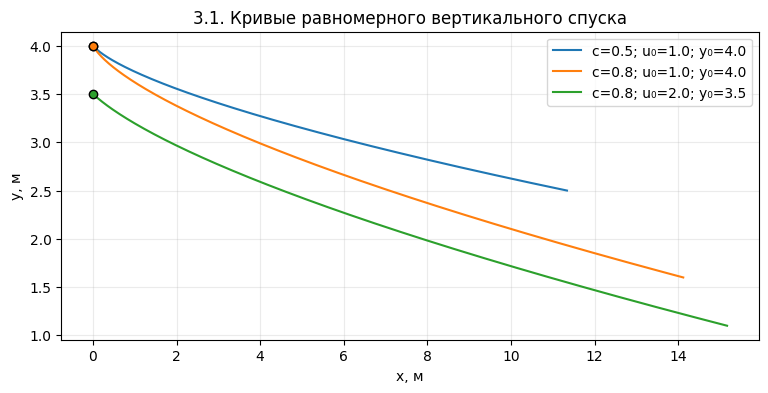

v_y = -0.8 м/с; разброс E = 1.42e-14 Дж (m=1 кг).


In [2]:
def descent(t, c=0.8, u0=1.0, x0=0.0, y0=4.0):
    t = np.asarray(t)
    u = np.sqrt(u0**2 + 2*g*c*t)
    x = x0 + (u**3 - u0**3)/(3*g*c)
    y = y0 - c*t
    return x, y, u

fig, ax = plt.subplots(figsize=(9, 4))
for c, u0, y0 in [(0.5, 1.0, 4.0), (0.8, 1.0, 4.0), (0.8, 2.0, 3.5)]:
    t = np.linspace(0, 3, 300)
    x, y, u = descent(t, c, u0, y0=y0)
    line, = ax.plot(x, y, label=f'c={c}; u₀={u0}; y₀={y0}')
    ax.scatter(x[0], y[0], color=line.get_color(), edgecolor='black', zorder=5)
ax.set(xlabel='x, м', ylabel='y, м', title='3.1. Кривые равномерного вертикального спуска')
ax.legend()
save_figure(fig, '3_1_descent.png')

# Проверка вертикальной скорости, явной формулы и энергии (m=1 кг).
t = np.linspace(0, 3, 501)
x, y, u = descent(t)
y_explicit = 4 + 1/(2*g) - (1 + 3*g*0.8*x)**(2/3)/(2*g)
energy = (u**2 + 0.8**2)/2 + g*y
assert np.allclose(np.gradient(y, t), -0.8)
assert np.allclose(y, y_explicit)
assert np.ptp(energy) < 1e-10
print(f'v_y = -0.8 м/с; разброс E = {np.ptp(energy):.2e} Дж (m=1 кг).')

In [3]:
t_desc = np.linspace(0, 3, 100)
xd, yd, ud = descent(t_desc)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(xd, yd, color='steelblue', label='Направляющая')
point, = ax.plot([], [], 'o', color='crimson', ms=10)
trace, = ax.plot([], [], color='crimson', lw=2)
info = ax.text(0.02, 0.04, '', transform=ax.transAxes)
ax.set(xlim=(-0.3, xd[-1]+0.5), ylim=(1.1, 4.5), xlabel='x, м', ylabel='y, м',
       title='Постоянная вертикальная скорость')
ax.legend(loc='upper right')
def update_descent(i):
    point.set_data([xd[i]], [yd[i]])
    trace.set_data(xd[:i+1], yd[:i+1])
    info.set_text(f't={t_desc[i]:.2f} с; v_y=-0.80 м/с; v_x={ud[i]:.2f} м/с')
    return point, trace, info
anim_descent = show_animation(fig, update_descent, len(t_desc))

**Результат 3.1.** Найдена полукубическая парабола. При движении по выбранной ветви высота убывает линейно, горизонтальная скорость возрастает, полная энергия сохраняется.

# 3. Задание 3.2. Бильярд в прямоугольнике

## Уравнения движения и отражения
Область: $0\leq x\leq a$, $0\leq y\leq b$. Между ударами
$$\ddot x=\ddot y=0,\qquad x=x_0+v_xt,\quad y=y_0+v_yt.$$
На вертикальной стенке $(v_x,v_y)\mapsto(-v_x,v_y)$, на горизонтальной $(v_x,v_y)\mapsto(v_x,-v_y)$. Сохраняются скорость и энергия $m(v_x^2+v_y^2)/2$.
В точном попадании в угол нормаль не единственна: для обычного бильярда это особый случай. Ниже выбраны данные без попаданий в углы; формула свёртки при попадании в угол условно меняет знаки обеих компонент.

## Метод развёртки
Вместо отражения шара отражаем прямоугольник и продолжаем прямую:
$$X(t)=x_0+v_xt,\qquad Y(t)=y_0+v_yt.$$
Сворачиваем прямую в исходную область треугольной волной
$$F_L(z)=L-\left|((z\bmod 2L)-L)\right|.$$
Точное решение:
$$\boxed{x(t)=F_a(X(t)),\qquad y(t)=F_b(Y(t))}.$$
Метод не накапливает ошибку отражений при большом шаге времени. Для статических ломаных дополнительно включаем в сетку точные моменты ударов, чтобы сегменты не срезали углы траектории.

## Тор, периодичность и эргодичность
Развёрнутое движение по модулю $(2a,2b)$ задаёт движение на плоском торе:
$$u=\frac{X\bmod 2a}{2a},\qquad w=\frac{Y\bmod 2b}{2b}.$$
При $v_xv_y\ne0$ полный фазовый возврат происходит, когда
$$v_xT=2an,\quad v_yT=2bm,\quad m,n\in\mathbb Z.$$
Следовательно, периодичность эквивалентна рациональности
$$\boxed{\rho=\frac{a v_y}{b v_x}\in\mathbb Q}.$$
Если $\rho=m/n$ в несократимом виде и скорости положительны, то $T=2an/v_x=2bm/v_y$. Осевая траектория также периодична (если не лежит на стенке).

При иррациональном $\rho$ орбита плотна на торе и её временные средние совпадают с пространственными средними относительно равномерной меры. После свёртки посещения равномерно распределяются по прямоугольнику. Это утверждение для **фиксированного направления на инвариантном торе**; весь бильярд на полной энергетической поверхности не эргодичен, поскольку сохраняются $|v_x|$ и $|v_y|$. Иррациональное направление не даёт хаоса: прямоугольный бильярд интегрируем. Конечный рисунок лишь иллюстрирует плотность, но не доказывает её.

## Гамильтонова формулировка
Внутри области
$$H=\frac{p_x^2+p_y^2}{2m},\quad \dot x=p_x/m,\quad \dot y=p_y/m,\quad
\dot p_x=\dot p_y=0.$$
Стенки можно описать бесконечным потенциальным барьером; удар мгновенно меняет знак нормального импульса. На развёрнутом торе движение свободное, без ударов.

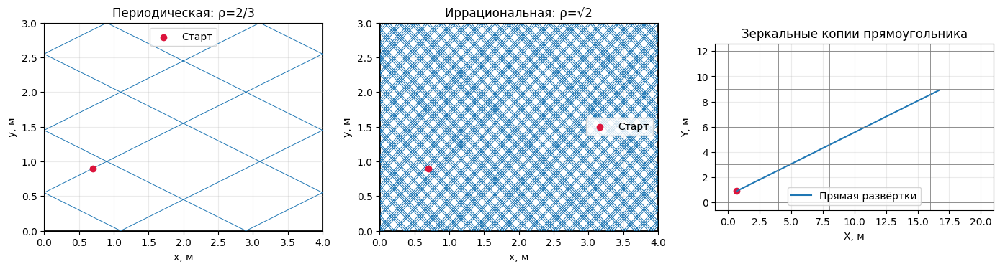

Период для ρ=2/3: T=24.0 с; положение вернулось к начальному.


In [4]:
a, b = 4.0, 3.0
bx0, by0 = 0.7, 0.9
vx = 1.0
vy_periodic = (b/a)*(2/3)       # Нормированный наклон rho=2/3.
vy_irrational = (b/a)*np.sqrt(2)
T_billiard = 2*a*3/vx

def fold(z, L):
    return L - np.abs(np.mod(z, 2*L)-L)

def billiard(t, vy):
    t = np.asarray(t)
    return fold(bx0+vx*t, a), fold(by0+vy*t, b)

def collision_grid(tmax, vy, samples=1500):
    """Добавляем времена контакта со стенками к обычной сетке."""
    ts = [np.linspace(0, tmax, samples)]
    for q0, vel, L in [(bx0, vx, a), (by0, vy, b)]:
        if vel == 0:
            continue
        lo, hi = sorted((q0, q0+vel*tmax))
        levels = np.arange(np.floor(lo/L), np.ceil(hi/L)+1)*L
        hit = (levels-q0)/vel
        ts.append(hit[(hit > 0) & (hit < tmax)])
    return np.unique(np.concatenate(ts))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, vy, tmax, title in [
    (axes[0], vy_periodic, T_billiard, 'Периодическая: ρ=2/3'),
    (axes[1], vy_irrational, 350, 'Иррациональная: ρ=√2')]:
    ts = collision_grid(tmax, vy)
    xx, yy = billiard(ts, vy)
    ax.plot(xx, yy, lw=0.7)
    ax.scatter([bx0], [by0], color='crimson', label='Старт', zorder=5)
    ax.add_patch(Rectangle((0, 0), a, b, fill=False, lw=2))
    ax.set(xlabel='x, м', ylabel='y, м', title=title, xlim=(0,a), ylim=(0,b))
    ax.set_aspect('equal'); ax.legend()
ax = axes[2]
ts = np.linspace(0, 16, 100)
ax.plot(bx0+vx*ts, by0+vy_periodic*ts, label='Прямая развёртки')
for j in range(6): ax.axvline(j*a, color='gray', lw=0.6)
for j in range(5): ax.axhline(j*b, color='gray', lw=0.6)
ax.scatter([bx0], [by0], color='crimson')
ax.set(xlabel='X, м', ylabel='Y, м', title='Зеркальные копии прямоугольника')
ax.set_aspect('equal'); ax.legend()
fig.tight_layout()
save_figure(fig, '3_2_billiard.png')
assert np.allclose(billiard(T_billiard, vy_periodic), (bx0, by0))
print(f'Период для ρ=2/3: T={T_billiard:.1f} с; положение вернулось к начальному.')

In [5]:
# Две строки: рациональный и иррациональный наклоны.
# Третий столбец показывает тот же плоский тор, вложенный в 3D.
t_bill = np.linspace(0, T_billiard, 120)
fig = plt.figure(figsize=(12, 6))
rows = []
phi_grid, psi_grid = np.meshgrid(np.linspace(0, 2*np.pi, 28),
                                np.linspace(0, 2*np.pi, 14))
def torus_xyz(u, w):
    phi, psi = 2*np.pi*u, 2*np.pi*w
    return ((2+0.65*np.cos(psi))*np.cos(phi),
            (2+0.65*np.cos(psi))*np.sin(phi), 0.65*np.sin(psi))
for row, (vy, label) in enumerate([(vy_periodic, 'ρ=2/3'), (vy_irrational, 'ρ=√2')]):
    ax1 = fig.add_subplot(2, 3, row*3+1)
    ax2 = fig.add_subplot(2, 3, row*3+2)
    ax3 = fig.add_subplot(2, 3, row*3+3, projection='3d')
    ax1.add_patch(Rectangle((0,0), a,b, fill=False))
    ax1.set(xlim=(0,a), ylim=(0,b), title=f'Бильярд, {label}', xlabel='x', ylabel='y')
    ax1.set_aspect('equal')
    path, = ax1.plot([], [], lw=1)
    ball, = ax1.plot([], [], 'ro', ms=6)
    ax2.set(xlim=(0,26), ylim=(0,28), title='Развёртка', xlabel='X', ylabel='Y')
    for k in range(8):
        ax2.axvline(k*a, color='gray', lw=0.5)
        ax2.axhline(k*b, color='gray', lw=0.5)
    unfolded, = ax2.plot([], [], color='steelblue')
    moving, = ax2.plot([], [], 'ro')
    ax3.plot_wireframe(*torus_xyz(phi_grid/(2*np.pi), psi_grid/(2*np.pi)),
                      color='gray', alpha=0.25, linewidth=0.4)
    ax3.set(xlim=(-3,3), ylim=(-3,3), zlim=(-1,1), title='Тор: (X mod 2a, Y mod 2b)')
    ax3.set_axis_off()
    tor_path, = ax3.plot([], [], [], lw=1)
    tor_ball, = ax3.plot([], [], [], 'ro', ms=6)
    rows.append((vy, path, ball, unfolded, moving, tor_path, tor_ball))
info = fig.text(0.5, 0.02, '', ha='center')
fig.tight_layout(rect=(0,0.05,1,1))
def update_billiard(i):
    ti = t_bill[i]
    for vy, path, ball, unfolded, moving, tor_path, tor_ball in rows:
        dense = collision_grid(ti, vy, samples=max(2, i*5))
        xx, yy = billiard(dense, vy)
        path.set_data(xx, yy); ball.set_data([xx[-1]], [yy[-1]])
        XX, YY = bx0+vx*dense, by0+vy*dense
        unfolded.set_data(XX, YY); moving.set_data([XX[-1]], [YY[-1]])
        tx, ty, tz = torus_xyz(XX/(2*a), YY/(2*b))
        tor_path.set_data_3d(tx,ty,tz)
        tor_ball.set_data_3d([tx[-1]],[ty[-1]],[tz[-1]])
    info.set_text(f't={ti:.2f} с; отражения сохраняют |v|; период верхней траектории {T_billiard:.0f} с')
    return ()
anim_billiard = show_animation(fig, update_billiard, len(t_bill), 60)

**Результат 3.2.** При рациональном нормированном наклоне траектория замкнута. Иррациональное направление порождает непериодическую плотную орбиту. Метод развёртки одновременно объясняет отражения и сводит задачу к свободному движению на торе.

# 4. Задание 3.3. Цепная линия

## Вывод уравнения равновесия
Рассмотрим однородную гибкую нерастяжимую цепь с линейной плотностью $\lambda$ (кг/м). Её вес на единицу длины $q=\lambda g$. Натяжение направлено по касательной. Горизонтальная составляющая натяжения постоянна: $H>0$.

Вертикальная составляющая $V=H\tan\alpha=Hy'$. Для элемента цепи
$$dV=q\,ds=q\sqrt{1+(y')^2}\,dx.$$
Поэтому
$$Hy''=q\sqrt{1+(y')^2},\qquad
\boxed{y''=\frac1a\sqrt{1+(y')^2}},\qquad a=\frac{H}{\lambda g}.$$

## Решение разделением переменных
Пусть $p=y'$. Тогда
$$\frac{dp}{\sqrt{1+p^2}}=\frac{dx}{a},\qquad
\operatorname{arsinh}p=\frac{x-x_c}{a},\quad
p=\sinh\frac{x-x_c}{a}.$$
Ещё одно интегрирование:
$$\boxed{y(x)=a\cosh\frac{x-x_c}{a}+C}.$$
При $x_c=0$, $C=0$ получаем требуемый вид $y=a\,\mathrm{ch}(x/a)$. Физическая высота определяется выбором $C$.

Пусть опоры одинаковой высоты $h$ находятся в $x=\pm d$. Тогда
$$y(x)=h+a\left(\cosh\frac xa-\cosh\frac da\right).$$
Провисание, длина и натяжение:
$$\delta=a\left(\cosh\frac da-1\right),\qquad
L=2a\sinh\frac da,\qquad T(x)=H\cosh\frac xa.$$
В нижней точке $T_{\min}=H$. Параметр $a$ имеет размерность длины: при фиксированной плотности больший $H$ увеличивает $a$ и уменьшает провисание; при фиксированном $H$ увеличение $\lambda$ уменьшает $a$ и увеличивает провисание.

**Ограничение нерастяжимости:** для одной цепи фиксированной длины $L$ и закреплённых опор параметр $a$ определяется уравнением длины. Тогда изменение только плотности меняет натяжение, но не форму. Анимация ниже показывает **семейство разных равновесий** с одинаковыми опорами и разными длинами цепи (как при выдаче/подтягивании цепи). Это не динамика растяжения одной нерастяжимой цепи.

## Силы на небольшом участке
Для концов $x_1<x_2$ силы натяжения, действующие на участок, равны
$$\mathbf T_1=(-H,-Hy'(x_1)),\quad \mathbf T_2=(H,Hy'(x_2)).$$
Его вес $\mathbf W=(0,-q\Delta s)$, где
$$\Delta s=a\left[\sinh(x_2/a)-\sinh(x_1/a)\right].$$
Их сумма равна нулю. В анимации стрелки этих сил имеют общий масштаб.

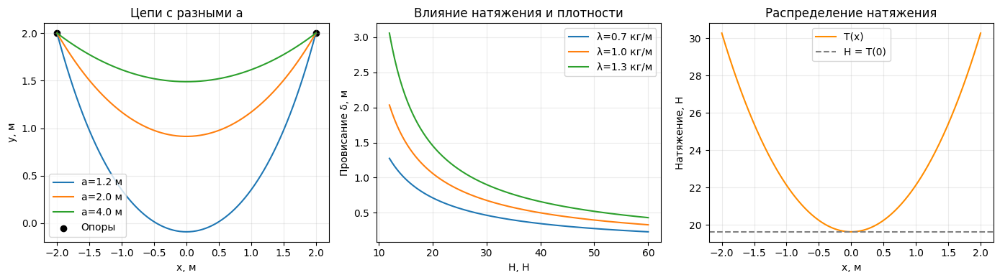

a=1.2 м: δ=2.0900 м; L=6.1267 м
a=2.0 м: δ=1.0862 м; L=4.7008 м
a=4.0 м: δ=0.5105 м; L=4.1688 м


In [6]:
d, h = 2.0, 2.0
xx_chain = np.linspace(-d, d, 401)
def chain_y(x, scale):
    return h + scale*(np.cosh(np.asarray(x)/scale)-np.cosh(d/scale))
def sag(scale):
    return scale*(np.cosh(d/scale)-1)
def chain_length(scale):
    return 2*scale*np.sinh(d/scale)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for scale in [1.2, 2.0, 4.0]:
    axes[0].plot(xx_chain, chain_y(xx_chain, scale), label=f'a={scale} м')
axes[0].scatter([-d,d], [h,h], color='black', label='Опоры')
axes[0].set(xlabel='x, м', ylabel='y, м', title='Цепи с разными a')
axes[0].legend()
H_values = np.linspace(12,60,200)
for density in [0.7, 1.0, 1.3]:
    axes[1].plot(H_values, sag(H_values/(density*g)), label=f'λ={density} кг/м')
axes[1].set(xlabel='H, Н', ylabel='Провисание δ, м', title='Влияние натяжения и плотности')
axes[1].legend()
scale, density = 2.0, 1.0
H = scale*density*g
axes[2].plot(xx_chain, H*np.cosh(xx_chain/scale), color='darkorange', label='T(x)')
axes[2].axhline(H, ls='--', color='gray', label='H = T(0)')
axes[2].set(xlabel='x, м', ylabel='Натяжение, Н', title='Распределение натяжения')
axes[2].legend()
fig.tight_layout()
save_figure(fig, '3_3_catenary.png')
for scale in [1.2,2,4]:
    numeric_length = quad(lambda x: np.cosh(x/scale), -d,d)[0]
    assert np.isclose(numeric_length, chain_length(scale))
    print(f'a={scale:.1f} м: δ={sag(scale):.4f} м; L={chain_length(scale):.4f} м')

In [7]:
phases = np.linspace(0, 2*np.pi, 100)
fig, ax = plt.subplots(figsize=(8, 4))
chain_line, = ax.plot([], [], lw=2.5, color='steelblue')
segment, = ax.plot([], [], lw=5, color='orange', label='Рассматриваемый участок')
ax.scatter([-d,d],[h,h],color='black',zorder=5,label='Опоры')
ax.set(xlim=(-2.8,2.8), ylim=(-1.0,3.5), xlabel='x, м', ylabel='y, м',
       title='Семейство равновесий цепи и баланс сил')
ax.legend(loc='upper left', fontsize=8)
info = ax.text(0.02,0.02,'', transform=ax.transAxes,fontsize=9)
# Постоянный общий масштаб стрелок: 0.025 м/Н.
x1, x2 = 0.45, 1.15
force_arrows = []
for color, label in [('crimson','T₁'), ('green','T₂'), ('purple','W')]:
    force_arrows.append(ax.annotate(label, xy=(0,0), xytext=(0,0), color=color,
                                   arrowprops=dict(arrowstyle='->', color=color, lw=2)))
def update_chain(i):
    phase = phases[i]
    HH = 24 + 5*np.sin(phase)
    density = 0.9 + 0.15*np.cos(phase)
    scale = HH/(density*g)
    chain_line.set_data(xx_chain, chain_y(xx_chain,scale))
    xs = np.linspace(x1,x2,40)
    segment.set_data(xs,chain_y(xs,scale))
    length_segment = scale*(np.sinh(x2/scale)-np.sinh(x1/scale))
    # Центр тяжести участка для приложения веса.
    xcm = quad(lambda x: x*np.cosh(x/scale), x1,x2)[0]/length_segment
    ycm = quad(lambda x: chain_y(x,scale)*np.cosh(x/scale), x1,x2)[0]/length_segment
    origins = [(x1,chain_y(x1,scale)), (x2,chain_y(x2,scale)), (xcm,ycm)]
    forces = [np.array([-HH,-HH*np.sinh(x1/scale)]),
              np.array([HH,HH*np.sinh(x2/scale)]),
              np.array([0,-density*g*length_segment])]
    for arrow, origin, force in zip(force_arrows, origins, forces):
        arrow.set_position(origin)
        arrow.xy = np.asarray(origin) + 0.025*force
    info.set_text(f'H={HH:.2f} Н; λ={density:.2f} кг/м; a={scale:.2f} м; '
                  f'δ={sag(scale):.2f} м; L={chain_length(scale):.2f} м')
    assert np.linalg.norm(np.sum(forces,axis=0)) < 1e-10
    return ()
anim_chain = show_animation(fig, update_chain, len(phases))

**Результат 3.3.** Равновесная форма однородной цепи является цепной линией. Форму определяет отношение горизонтального натяжения к весу единицы длины; силы натяжения и тяжести каждого участка взаимно уравновешены.

# 5. Задание 3.4. Таутохрона

## Интегральное уравнение времени спуска
Нижняя точка имеет координаты $(0,0)$. Рассматриваем правую ветвь; $s\geq0$ — длина дуги от нижней точки, $y\geq0$ — высота. Точку отпускают без начальной скорости с высоты $h$.

Из сохранения энергии:
$$v=\sqrt{2g(h-y)}.$$
Время спуска:
$$T(h)=\frac1{\sqrt{2g}}\int_0^h\frac{s'(y)}{\sqrt{h-y}}\,dy.$$
Условие таутохронности $T(h)=T_*$ даёт уравнение Абеля:
$$\int_0^h\frac{\phi(y)}{\sqrt{h-y}}\,dy=\sqrt{2g}\,T_*,\qquad \phi(y)=s'(y).$$

## Обращение уравнения Абеля
Применяем формулу обращения:
$$\phi(y)=\frac1\pi\frac d{dy}\int_0^y
\frac{\sqrt{2g}T_*}{\sqrt{y-h}}\,dh
=\frac{\sqrt{2g}T_*}{\pi\sqrt y}.$$
С условием $s(0)=0$:
$$s(y)=\frac{2\sqrt{2g}T_*}{\pi}\sqrt y,\qquad
\boxed{y=\frac{\pi^2s^2}{8gT_*^2}}.$$
Вводим $R=gT_*^2/\pi^2$. Тогда
$$y=\frac{s^2}{8R},\qquad T_*=\pi\sqrt{R/g}.$$
Так как $|dy/ds|\leq1$, физическая ветвь ограничена $0\leq s\leq4R$, $0\leq y\leq2R$.

## Восстановление кривой
Положим $s=4R\sin(\theta/2)$, $-\pi<\theta<\pi$, используя знаковую координату дуги для двух ветвей. Получаем
$$y=R(1-\cos\theta),\qquad ds=2R\cos(\theta/2)\,d\theta.$$
Из $dx^2+dy^2=ds^2$:
$$\frac{dx}{d\theta}=R(1+\cos\theta).$$
После интегрирования при $x(0)=0$:
$$\boxed{x=R(\theta+\sin\theta),\qquad y=R(1-\cos\theta)}.$$
Это перевёрнутая циклоида с нижней точкой в начале координат. Граничные точки $\theta=\pm\pi$ — острия; старты выбираем строго внутри гладкой части.

## Доказательство одинакового времени
Проекция тяжести на дугу:
$$\ddot s=-g\frac{dy}{ds}=-\frac g{4R}s.$$
Это гармонический осциллятор с частотой $\omega_c=\sqrt{g/(4R)}$. При $s(0)=s_0$, $\dot s(0)=0$:
$$s(t)=s_0\cos(\omega_ct).$$
Первый приход в нижнюю точку происходит через четверть периода:
$$\boxed{T_* =\frac{\pi}{2\omega_c}=\pi\sqrt{R/g}},$$
независимо от $s_0\ne0$. Старт из самой нижней точки вырожден: точка уже в месте назначения.

## Геометрическое построение
Окружность радиуса $R$ с центром $(R\theta,R)$ катится без проскальзывания **под** горизонтальной направляющей $y=2R$. Радиус к отмеченной точке равен $(R\sin\theta,-R\cos\theta)$, поэтому точка окружности описывает найденную циклоиду. Скорость верхней точки контакта равна нулю. Эта геометрическая окружность не является скользящим телом.

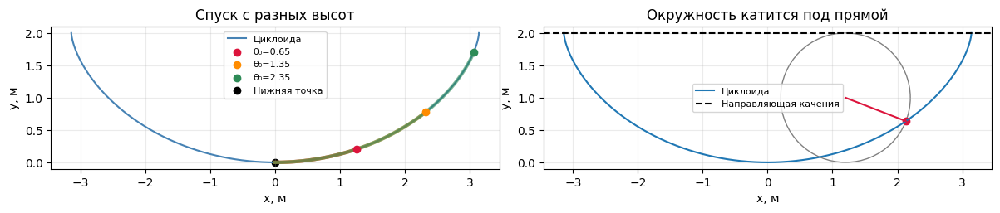

θ₀=0.65; h=0.2039 м; T=1.00303334 с
θ₀=1.35; h=0.7810 м; T=1.00303334 с
θ₀=2.35; h=1.7027 м; T=1.00303334 с
Общее аналитическое время спуска: 1.00303334 с.


In [8]:
R = 1.0
omega_c = np.sqrt(g/(4*R))
T_tauto = np.pi*np.sqrt(R/g)
def cycloid(theta):
    theta = np.asarray(theta)
    return R*(theta+np.sin(theta)), R*(1-np.cos(theta))

theta_curve = np.linspace(-np.pi,np.pi,600)
start_angles = np.array([0.65,1.35,2.35])
s0s = 4*R*np.sin(start_angles/2)
colors = ['crimson','darkorange','seagreen']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(*cycloid(theta_curve), color='steelblue', label='Циклоида')
for theta0,color in zip(start_angles,colors):
    axes[0].plot(*cycloid(np.linspace(0,theta0,100)),color=color,lw=3,alpha=0.6)
    axes[0].scatter(*cycloid(theta0),color=color,zorder=5,label=f'θ₀={theta0:.2f}')
axes[0].scatter(0,0,color='black',label='Нижняя точка')
axes[0].set(xlabel='x, м',ylabel='y, м',title='Спуск с разных высот')
axes[0].set_aspect('equal'); axes[0].legend(fontsize=8)
angle_build = 1.2
center = np.array([R*angle_build,R])
point_build = np.array(cycloid(angle_build))
axes[1].plot(*cycloid(theta_curve),label='Циклоида')
axes[1].add_patch(Circle(center,R,fill=False,color='gray'))
axes[1].axhline(2*R,color='black',ls='--',label='Направляющая качения')
axes[1].plot([center[0],point_build[0]],[center[1],point_build[1]],color='crimson')
axes[1].scatter(*point_build,color='crimson')
axes[1].set(xlabel='x, м',ylabel='y, м',title='Окружность катится под прямой')
axes[1].set_aspect('equal'); axes[1].legend(fontsize=8)
fig.tight_layout()
save_figure(fig,'3_4_tautochrone.png')

# Подстановка y=h sin²(u) устраняет обе особенности интеграла времени.
for theta0 in start_angles:
    height = R*(1-np.cos(theta0))
    time_numeric = quad(lambda u: 2*np.sqrt(R/g),0,np.pi/2)[0]
    assert np.isclose(time_numeric,T_tauto)
    print(f'θ₀={theta0:.2f}; h={height:.4f} м; T={time_numeric:.8f} с')
print(f'Общее аналитическое время спуска: {T_tauto:.8f} с.')

In [9]:
# Независимая проверка таутохронности: численно находим событие s(t)=0.
def bottom_event(t, state):
    return state[0]
bottom_event.direction = -1
bottom_event.terminal = True
print('Проверка времени прихода решением ОДУ:')
for start_angle, initial_arc in zip(start_angles, s0s):
    flight = solve_ivp(lambda t,z: [z[1], -omega_c**2*z[0]],
                       (0,2*T_tauto), [initial_arc,0.0],
                       events=bottom_event, rtol=1e-10, atol=1e-12,
                       max_step=T_tauto/100)
    arrival = flight.t_events[0][0]
    assert np.isclose(arrival,T_tauto,rtol=1e-8)
    print(f'θ₀={start_angle:.2f}: t прихода={arrival:.10f} с; '
          f'отклонение от T*={abs(arrival-T_tauto):.2e} с')

Проверка времени прихода решением ОДУ:
θ₀=0.65: t прихода=1.0030333404 с; отклонение от T*=1.11e-14 с
θ₀=1.35: t прихода=1.0030333404 с; отклонение от T*=9.10e-15 с
θ₀=2.35: t прихода=1.0030333404 с; отклонение от T*=2.86e-14 с


In [10]:
t_tau = np.linspace(0,T_tauto,100)
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(*cycloid(theta_curve),color='steelblue')
balls = [axes[0].plot([],[],'o',color=c,ms=9,label=f'θ₀={th:.2f}')[0]
         for c,th in zip(colors,start_angles)]
axes[0].set(xlim=(-0.4,3.4),ylim=(-0.2,2.2),xlabel='x, м',ylabel='y, м',
            title='Все точки приходят одновременно')
axes[0].legend(fontsize=8); axes[0].set_aspect('equal')
axes[1].plot(*cycloid(theta_curve),label='Циклоида')
axes[1].axhline(2*R,color='black',ls='--')
rolling_circle = Circle((0,R),R,fill=False,color='gray',lw=2)
axes[1].add_patch(rolling_circle)
radius_line, = axes[1].plot([],[],color='crimson')
generator, = axes[1].plot([],[],'ro')
axes[1].set(xlim=(-4.5,4.5),ylim=(-0.3,2.5),xlabel='x, м',ylabel='y, м',
            title='Построение катящейся окружностью')
axes[1].set_aspect('equal')
info = fig.text(0.5,0.02,'',ha='center')
fig.tight_layout(rect=(0,0.08,1,1))
def update_tautochrone(i):
    time = t_tau[i]
    for ball,s0 in zip(balls,s0s):
        s = s0*np.cos(omega_c*time)
        theta = 2*np.arcsin(np.clip(s/(4*R),-1,1))
        x,y = cycloid(theta)
        ball.set_data([x],[y])
    theta = -np.pi + 2*np.pi*i/(len(t_tau)-1)
    cx,cy = R*theta,R
    px,py = cycloid(theta)
    rolling_circle.center = (cx,cy)
    radius_line.set_data([cx,px],[cy,py]); generator.set_data([px],[py])
    status = 'ВСЕ В НИЖНЕЙ ТОЧКЕ' if i==len(t_tau)-1 else 'идёт спуск'
    info.set_text(f't={time:.3f} с; T*={T_tauto:.3f} с; {status}')
    return ()
anim_tautochrone = show_animation(fig,update_tautochrone,len(t_tau))

**Результат 3.4.** Таутохроной является циклоида. Координата длины дуги подчиняется гармоническому закону, поэтому время первого спуска равно четверти периода и не зависит от ненулевой начальной высоты.

# 6. Задание 3.5. Математический маятник

## Вывод нелинейного уравнения
Точечная масса $m$ закреплена на невесомом жёстком стержне длины $\ell$. Угол $\theta$ отсчитываем от вертикали вниз. Касательная составляющая силы тяжести $-mg\sin\theta$, касательное ускорение $\ell\ddot\theta$:
$$m\ell\ddot\theta=-mg\sin\theta,\qquad
\boxed{\ddot\theta+\frac g\ell\sin\theta=0}.$$
Система первого порядка:
$$\dot\theta=\omega,\qquad \dot\omega=-\frac g\ell\sin\theta.$$
Энергия и гамильтониан:
$$E=\frac12m\ell^2\omega^2+mg\ell(1-\cos\theta),$$
$$p=m\ell^2\omega,\qquad H=\frac{p^2}{2m\ell^2}+mg\ell(1-\cos\theta).$$

## Малые колебания
При $|\theta|\ll1$ (угол в радианах) $\sin\theta\approx\theta$. Обозначим $\omega_0=\sqrt{g/\ell}$. Тогда
$$\theta_{\rm lin}(t)=\theta_0\cos\omega_0t+\frac{\omega(0)}{\omega_0}\sin\omega_0t,
\qquad T_0=2\pi\sqrt{\ell/g}.$$
Линейная модель предсказывает период, не зависящий от амплитуды; это приближение для малых углов.

## Нелинейное решение и эллиптический интеграл
Для старта из покоя с амплитуды $A\in(0,\pi)$:
$$\omega^2=\frac{2g}{\ell}(\cos\theta-\cos A).$$
Разделение переменных и подстановка $\sin(\theta/2)=k\sin\varphi$, $k=\sin(A/2)$ дают
$$\frac T4=\sqrt{\frac\ell g}\int_0^{\pi/2}
\frac{d\varphi}{\sqrt{1-k^2\sin^2\varphi}},$$
$$\boxed{T(A)=4\sqrt{\ell/g}\,K(k)}.$$
Разложение для малых амплитуд:
$$T(A)=T_0\left(1+\frac{A^2}{16}+\frac{11A^4}{3072}+\cdots\right).$$
При $A\to\pi$ период неограниченно растёт.

Точное решение через эллиптическую функцию Якоби для $\theta(0)=A$, $\omega(0)=0$:
$$\boxed{\theta(t)=2\arcsin\left[k\,\operatorname{sn}\bigl(K(k)-\omega_0t,k\bigr)\right]}.$$
Во втором аргументе `scipy.special.ellipj` также используется $m=k^2$. Численное решение ниже сравниваем с этой формулой.

## Фазовый портрет и режимы
Энергия покоя в нижней точке равна нулю; энергия верхней точки $E_s=2mg\ell$.

- $E=0$: устойчивое равновесие $(\theta,\omega)=(2\pi n,0)$.
- $0<E<E_s$: колебания, замкнутые фазовые кривые.
- $E=E_s$: сепаратриса и неустойчивые верхние равновесия $((2n+1)\pi,0)$.
- $E>E_s$: вращения; возможны при жёстком стержне, как в условии листка.

На интервале $-\pi\leq\theta\leq\pi$ сепаратрисы:
$$\boxed{\omega=\pm2\sqrt{g/\ell}\cos(\theta/2)}.$$
Физическая фазовая поверхность — цилиндр по углу; на рисунке показана его развёртка. Верхнее равновесие не достигается по сепаратрисе за конечное время.

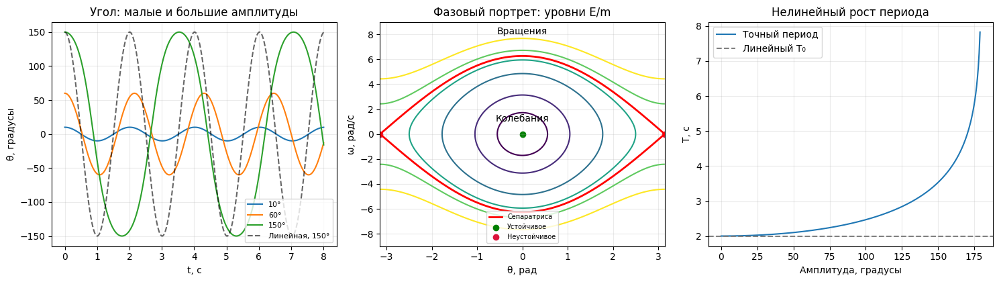

Период малых колебаний: T₀=2.00606668 с
A= 10°: T=2.009893 с; T числ.=2.009893 с; ошибка θ=2.16e-14 рад; отн. дрейф E=2.02e-13
A= 60°: T=2.152875 с; T числ.=2.152875 с; ошибка θ=6.64e-13 рад; отн. дрейф E=1.86e-12
A=150°: T=3.535098 с; T числ.=3.535098 с; ошибка θ=5.32e-11 рад; отн. дрейф E=8.11e-12


In [11]:
ell = 1.0
w0 = np.sqrt(g/ell)
T0 = 2*np.pi/w0

def pendulum_rhs(t, state):
    theta, omega = state
    return [omega, -(g/ell)*np.sin(theta)]

def solve_pendulum(theta0, omega_init=0.0, tmax=8.0):
    sol = solve_ivp(pendulum_rhs, (0,tmax), [theta0,omega_init],
                    method='DOP853', rtol=1e-10, atol=1e-12, dense_output=True,
                    max_step=0.04)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

def pendulum_exact(t, amplitude):
    k = np.sin(amplitude/2)
    sn,cn,dn,ph = ellipj(ellipk(k*k)-w0*np.asarray(t),k*k)
    return 2*np.arcsin(np.clip(k*sn,-1,1))

def specific_energy(theta, omega):
    return 0.5*ell**2*np.asarray(omega)**2 + g*ell*(1-np.cos(theta))

t_pend = np.linspace(0,8,1200)
solutions = {A: solve_pendulum(np.deg2rad(A)) for A in [10,60,150]}
rotation_sol = solve_pendulum(0,2.4*w0)
fig, axes = plt.subplots(1,3,figsize=(15,4.3))
for deg,sol in solutions.items():
    th,om = sol.sol(t_pend)
    axes[0].plot(t_pend,np.rad2deg(th),label=f'{deg}°')
axes[0].plot(t_pend,150*np.cos(w0*t_pend),'k--',alpha=0.6,label='Линейная, 150°')
axes[0].set(xlabel='t, с',ylabel='θ, градусы',title='Угол: малые и большие амплитуды')
axes[0].legend(fontsize=8)
# Поле направлений и уровни энергии показывают все режимы.
TH, OM = np.meshgrid(np.linspace(-np.pi,np.pi,160),np.linspace(-9,9,180))
levels = g*ell*np.array([0.15,0.5,1.2,1.8,2.3,3.0])
cs = axes[1].contour(TH,OM,specific_energy(TH,OM),levels=levels,cmap='viridis')
theta_phase = np.linspace(-np.pi,np.pi,400)
for sign in [-1,1]:
    axes[1].plot(theta_phase,sign*2*w0*np.cos(theta_phase/2),'r-',lw=2,
                 label='Сепаратриса' if sign==1 else None)
axes[1].scatter([0],[0],color='green',label='Устойчивое')
axes[1].scatter([-np.pi,np.pi],[0,0],color='crimson',label='Неустойчивое')
axes[1].text(0,1,'Колебания',ha='center')
axes[1].text(0,8,'Вращения',ha='center')
axes[1].set(xlabel='θ, рад',ylabel='ω, рад/с',title='Фазовый портрет: уровни E/m')
axes[1].legend(fontsize=7,loc='lower center')
amplitudes = np.linspace(0,np.deg2rad(179),300)
periods = 4/w0*ellipk(np.sin(amplitudes/2)**2)
axes[2].plot(np.rad2deg(amplitudes),periods,label='Точный период')
axes[2].axhline(T0,color='gray',ls='--',label='Линейный T₀')
axes[2].set(xlabel='Амплитуда, градусы',ylabel='T, с',title='Нелинейный рост периода')
axes[2].legend()
fig.tight_layout()
save_figure(fig,'3_5_pendulum.png')

print(f'Период малых колебаний: T₀={T0:.8f} с')
for deg,sol in solutions.items():
    A = np.deg2rad(deg)
    th,om = sol.sol(t_pend)
    energy = specific_energy(th,om)
    exact_error = np.max(np.abs(th-pendulum_exact(t_pend,A)))
    relative_drift = np.max(np.abs(energy-energy[0]))/energy[0]
    period = 4/w0*ellipk(np.sin(A/2)**2)
    # Независимая численная оценка периода по двум максимумам: omega=0, + -> -.
    def turning_event(t,state):
        return state[1]
    turning_event.direction = -1
    check = solve_ivp(pendulum_rhs,(0,10),[A,0],events=turning_event,
                       rtol=1e-10,atol=1e-12,max_step=0.02)
    event_times = check.t_events[0]
    period_numeric = np.diff(event_times)[0]
    assert relative_drift < 1e-7
    assert exact_error < 1e-7
    assert np.isclose(period_numeric,period,rtol=1e-7)
    print(f'A={deg:3d}°: T={period:.6f} с; T числ.={period_numeric:.6f} с; '
          f'ошибка θ={exact_error:.2e} рад; отн. дрейф E={relative_drift:.2e}')

In [12]:
# Малые и большие колебания, а также вращение; физическое время общее.
t_anim_p = np.linspace(0,6,120)
animation_modes = [
    ('10°: почти гармонический',solutions[10]),
    ('150°: нелинейный',solutions[150]),
    ('Вращение',rotation_sol),
]
fig,axes = plt.subplots(2,3,figsize=(11,6))
pend_objects=[]
for j,(label,sol) in enumerate(animation_modes):
    config,phase = axes[0,j],axes[1,j]
    config.plot([0],[0],'ko',ms=4)
    rod, = config.plot([],[],'o-',lw=2,ms=9)
    config.set(xlim=(-1.2,1.2),ylim=(-1.3,1.2),title=label,xlabel='x, м',ylabel='y, м')
    config.set_aspect('equal')
    # Для вращения используем непрерывный развёрнутый угол.
    dense_times=np.linspace(0,6,800)
    th,om=sol.sol(dense_times)
    phase.plot(th,om,color='gray',alpha=0.3,lw=1)
    if j<2:
        phase.set_xlim(-np.pi,np.pi)
        for sign in [-1,1]:
            phase.plot(theta_phase,sign*2*w0*np.cos(theta_phase/2),'r--',lw=0.7)
    else:
        phase.set_xlim(-0.4,th[-1]+0.4)
    phase.set_ylim(-8.5,8.5)
    phase.set(xlabel='θ, рад',ylabel='ω, рад/с')
    history, = phase.plot([],[],lw=1.5)
    marker, = phase.plot([],[],'ro',ms=5)
    pend_objects.append((sol,rod,history,marker))
info = fig.text(0.5,0.015,'',ha='center')
fig.tight_layout(rect=(0,0.05,1,1))
def update_pendulum(i):
    time=t_anim_p[i]
    for sol,rod,history,marker in pend_objects:
        th,om=sol.sol(time)
        rod.set_data([0,ell*np.sin(th)],[0,-ell*np.cos(th)])
        th_hist,om_hist=sol.sol(t_anim_p[:i+1])
        history.set_data(th_hist,om_hist); marker.set_data([th],[om])
    info.set_text(f't={time:.2f} с; движение и фазовые точки синхронизированы')
    return ()
anim_pendulum=show_animation(fig,update_pendulum,len(t_anim_p))

**Результат 3.5.** Линейное приближение подходит для малых углов. В нелинейной модели период увеличивается с амплитудой; сепаратриса отделяет колебания от вращений. Численное решение согласуется с функциями Якоби и сохраняет энергию в пределах заданной точности.

# 7. Итоговые результаты

| Задача | Математический результат | Что проверено в Python |
|---|---|---|
| 3.1. Равномерный вертикальный спуск | Ветвь полукубической параболы | Постоянство вертикальной скорости, явная формула, сохранение энергии |
| 3.2. Бильярд | Прямая в развёртке; свёртка треугольной волной | Возврат периодической траектории; сравнение рационального и иррационального направлений |
| 3.3. Цепная линия | $y=a\cosh((x-x_c)/a)+C$ | Длина цепи; баланс трёх сил на участке при каждом кадре |
| 3.4. Таутохрона | Циклоида, $T_*=\pi\sqrt{R/g}$ | Равенство времён спуска; синхронный приход в анимации |
| 3.5. Маятник | $\ddot\theta+(g/\ell)\sin\theta=0$ | Сохранение энергии; сравнение с точным решением и эллиптическим периодом |

**Вывод.** Для всех пяти задач составлены уравнения и подробно получены решения. Построены статические рисунки и управляемые анимации. Показано, как законы Ньютона, равновесие сил, сохранение энергии и геометрия траектории позволяют исследовать механические системы аналитически и численно.

**Источник условий:** приложенный файл «Практические занятия Листок 3.pdf», задания 3.1–3.5. Формулы в работе выведены в соответствующих разделах.